# 04 Gradient Boosting (Section 5.3)
Owner: David, Marc Lawrence

Same split, 5 time-ordered folds and scoring as the other two models (`src/common.py`), and the same layout as the Logistic Regression notebook so the three can be compared. **The test days are never used here** (`final_test()` is not called). Choosing is done on the 5 folds only.

What is different from Logistic Regression: Gradient Boosting does not need scaled inputs (`make_preprocess(scale=False)`), and it has more settings to try (learning rate, tree depth, number of trees), plus sample weights (`none` or `balanced`) instead of `class_weight`.

In [1]:
import os, sys, subprocess, warnings, time
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, joblib

# Run inside the repo (notebooks/ folder), or in Colab: the repo is cloned next to the notebook.
if os.path.exists("../src/common.py"):
    ROOT = ".."
else:
    if not os.path.exists("heatcast-ncr-simple"):
        subprocess.run(["git", "clone", "--depth", "1", "https://github.com/keyyum/heatcast-ncr-simple"], check=True)
    ROOT = "heatcast-ncr-simple"
sys.path.append(f"{ROOT}/src")

from common import *
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.pipeline import make_pipeline
from sklearn.metrics import confusion_matrix
from sklearn.utils.class_weight import compute_sample_weight

df = load_data()
train, test = split_train_test(df)          # the test days are not touched below
print(f"train: {len(train):,} rows, {train['Date'].nunique():,} days ({train['Date'].min().date()} to {train['Date'].max().date()})")
print(f"test : {len(test):,} rows (not used)")
print("features:", FEATURES)

train: 23,312 rows, 1,457 days (2021-01-01 to 2024-12-27)
test : 5,840 rows (not used)
features: ['HeatIndex_Max_Today', 'Temp_Min', 'Rainfall_Total', 'Pressure_Mean', 'SolarRadiation_Total', 'City']


## 1. The rule to beat: "copy today"

In [2]:
baseline = summarize(persistence_cv(train))
baseline

,mean,sd
macro_f1,0.620,0.102
macro_f1_core3,0.679,0.051
accuracy,0.846,0.039
danger_recall,0.518,0.153
danger_precision,0.527,0.153


## 2. What I tried
Gradient Boosting (`GradientBoostingClassifier`) on the five weather inputs and City. City becomes 16 yes/no columns inside the pipeline (`make_preprocess(scale=False)`), so the encoder learns from each fold's training days only. I varied the learning rate (0.05, 0.1), the tree depth (2, 3), the number of trees (100, 200) and the sample weights (none, balanced), which gives 16 settings. `min_samples_leaf` was fixed at 20 to keep the trees from fitting tiny groups of days, and `random_state` is 42. Each setting is scored on the 5 time-ordered folds inside the training days.

In [3]:
LEARNING_RATES = [0.05, 0.1]
DEPTHS = [2, 3]
N_TREES = [100, 200]
WEIGHTS = ["none", "balanced"]

def balanced_weights(y):
    return {"gradientboostingclassifier__sample_weight": compute_sample_weight("balanced", y)}

def make_gb(lr, depth, n):
    return make_pipeline(make_preprocess(scale=False),
                         GradientBoostingClassifier(learning_rate=lr, max_depth=depth, n_estimators=n,
                                                    min_samples_leaf=20, random_state=RANDOM_STATE))

rows, folds_by_setting = [], {}
t0 = time.time()
for w in WEIGHTS:
    for lr in LEARNING_RATES:
        for depth in DEPTHS:
            for n in N_TREES:
                table = cross_validate(make_gb(lr, depth, n), train, fit_params=balanced_weights if w == "balanced" else None)
                s = summarize(table)
                folds_by_setting[(lr, depth, n, w)] = table
                rows.append({"learning_rate": lr, "max_depth": depth, "n_trees": n, "sample_weight": w,
                             "macro_f1_core3": s.loc["macro_f1_core3", "mean"], "danger_recall": s.loc["danger_recall", "mean"],
                             "danger_precision": s.loc["danger_precision", "mean"], "accuracy": s.loc["accuracy", "mean"],
                             "macro_f1": s.loc["macro_f1", "mean"]})
                print(f"{len(rows):>2}/16  lr={lr} depth={depth} trees={n} weight={w:<8} core3={rows[-1]['macro_f1_core3']:.3f}  ({time.time()-t0:.0f}s)")
results = pd.DataFrame(rows)

 1/16  lr=0.05 depth=2 trees=100 weight=none     core3=0.613  (14s)


 2/16  lr=0.05 depth=2 trees=200 weight=none     core3=0.610  (40s)


 3/16  lr=0.05 depth=3 trees=100 weight=none     core3=0.604  (58s)


 4/16  lr=0.05 depth=3 trees=200 weight=none     core3=0.599  (96s)


 5/16  lr=0.1 depth=2 trees=100 weight=none     core3=0.617  (109s)


...

12/16  lr=0.05 depth=3 trees=200 weight=balanced core3=0.629  (285s)


13/16  lr=0.1 depth=2 trees=100 weight=balanced core3=0.639  (299s)


14/16  lr=0.1 depth=2 trees=200 weight=balanced core3=0.643  (326s)


15/16  lr=0.1 depth=3 trees=100 weight=balanced core3=0.634  (345s)


16/16  lr=0.1 depth=3 trees=200 weight=balanced core3=0.641  (384s)


The score of each setting, averaged over the five folds (same columns as the Logistic Regression table):

In [4]:
show = results[["learning_rate", "max_depth", "n_trees", "sample_weight", "macro_f1_core3", "danger_recall", "danger_precision"]]
show.round(3).rename(columns={"macro_f1_core3": "Macro F1 (core 3)", "danger_recall": "Danger recall", "danger_precision": "Danger precision"})

,learning_rate,max_depth,n_trees,sample_weight,Macro F1 (core 3),Danger recall,Danger precision
0,0.05,2,100,none,0.613,0.269,0.572
1,0.05,2,200,none,0.610,0.266,0.551
2,0.05,3,100,none,0.604,0.267,0.554
3,0.05,3,200,none,0.599,0.242,0.521
4,0.10,2,100,none,0.617,0.271,0.556
5,0.10,2,200,none,0.608,0.251,0.510
6,0.10,3,100,none,0.596,0.241,0.519
7,0.10,3,200,none,0.598,0.257,0.530
8,0.05,2,100,balanced,0.624,0.785,0.325
9,0.05,2,200,balanced,0.642,0.753,0.356


## 3. Best setting
Chosen like the Logistic Regression notebook: the highest mean macro F1 over the three core levels, using the 5 folds only.

In [5]:
best_row = results.sort_values("macro_f1_core3", ascending=False).iloc[0]
best = (float(best_row["learning_rate"]), int(best_row["max_depth"]), int(best_row["n_trees"]), str(best_row["sample_weight"]))
print("best setting: learning_rate=%s, max_depth=%s, n_trees=%s, sample_weight=%s" % best)
best_table = folds_by_setting[best]
best_summary = summarize(best_table)
display(best_table.round(3))
display(best_summary)
print("copy-today rule:")
display(baseline)

best setting: learning_rate=0.1, max_depth=2, n_trees=200, sample_weight=balanced


,macro_f1,macro_f1_core3,accuracy,danger_recall,danger_precision
fold,,,,,
1,0.611,0.611,0.824,0.288,0.228
2,0.442,0.589,0.829,0.660,0.324
3,0.529,0.705,0.785,0.712,0.399
4,0.661,0.661,0.775,0.845,0.456
5,0.646,0.646,0.740,0.842,0.499


,mean,sd
macro_f1,0.578,0.092
macro_f1_core3,0.643,0.045
accuracy,0.790,0.037
danger_recall,0.670,0.228
danger_precision,0.381,0.108


copy-today rule:


,mean,sd
macro_f1,0.620,0.102
macro_f1_core3,0.679,0.051
accuracy,0.846,0.039
danger_recall,0.518,0.153
danger_precision,0.527,0.153


### Comparison on the 5 folds (mean ± SD)
The Logistic Regression row is copied from Section 5.1 of the group document.

In [6]:
def fmt(s, k): return f"{s.loc[k,'mean']:.3f} ± {s.loc[k,'sd']:.3f}"
comparison = pd.DataFrame({
    "Macro F1 (all levels / core 3)": [f"{fmt(baseline,'macro_f1')} / {fmt(baseline,'macro_f1_core3')}",
                                       "0.569 ± 0.095 / 0.632 ± 0.043",
                                       f"{fmt(best_summary,'macro_f1')} / {fmt(best_summary,'macro_f1_core3')}"],
    "Accuracy": [fmt(baseline,'accuracy'), "0.858 ± 0.038", fmt(best_summary,'accuracy')],
    "Danger recall": [fmt(baseline,'danger_recall'), "0.276 ± 0.101", fmt(best_summary,'danger_recall')],
    "Danger precision": [fmt(baseline,'danger_precision'), "0.655 ± 0.158", fmt(best_summary,'danger_precision')],
}, index=['"Copy today" rule (not a model)', "Logistic Regression", "Gradient Boosting"])
comparison

,Macro F1 (all levels / core 3),Accuracy,Danger recall,Danger precision
"""Copy today"" rule (not a model)",0.620 ± 0.102 / 0.679 ± 0.051,0.846 ± 0.039,0.518 ± 0.153,0.527 ± 0.153
Logistic Regression,0.569 ± 0.095 / 0.632 ± 0.043,0.858 ± 0.038,0.276 ± 0.101,0.655 ± 0.158
Gradient Boosting,0.578 ± 0.092 / 0.643 ± 0.045,0.790 ± 0.037,0.670 ± 0.228,0.381 ± 0.108


## 4. Confusion matrix of the chosen setting
Summed over the five check blocks, as for Logistic Regression. Rows are the true level, columns the predicted level. (The first fold's training days are never predicted, and the few Not Hazardous days are left out of the 3x3 view.)

In [7]:
X, y = train[FEATURES], train[TARGET]
y_true_all, y_pred_all = [], []
for fit_idx, check_idx in make_folds(train):
    m = make_gb(*best[:3])
    extra = balanced_weights(y.iloc[fit_idx]) if best[3] == "balanced" else {}
    m.fit(X.iloc[fit_idx], y.iloc[fit_idx], **extra)
    y_true_all += list(y.iloc[check_idx]); y_pred_all += list(m.predict(X.iloc[check_idx]))
y_true_all, y_pred_all = np.array(y_true_all), np.array(y_pred_all)

cm = pd.DataFrame(confusion_matrix(y_true_all, y_pred_all, labels=CORE_LEVELS),
                  index=[f"true {l}" for l in CORE_LEVELS], columns=[f"pred {l}" for l in CORE_LEVELS])
display(cm)
n_dropped = len(y_true_all) - cm.values.sum()
print(f"rows left out of the 3x3 view (Not Hazardous true or predicted): {n_dropped}")
danger_total = cm.loc["true Danger"].sum(); danger_caught = cm.loc["true Danger", "pred Danger"]
danger_called = cm["pred Danger"].sum()
print(f"Danger days: {danger_total:,}; caught {danger_caught:,} (pooled recall {danger_caught/danger_total:.0%}); "
      f"{danger_total-danger_caught:,} missed")
print(f"Days called Danger: {danger_called:,}; really Danger {danger_caught:,} (pooled precision {danger_caught/danger_called:.0%}); "
      f"false alarms {danger_called-danger_caught:,}")

,pred Caution,pred Extreme Caution,pred Danger
true Caution,1943,598,0
true Extreme Caution,1518,12166,1535
true Danger,0,363,1190


rows left out of the 3x3 view (Not Hazardous true or predicted): 47
Danger days: 1,553; caught 1,190 (pooled recall 77%); 363 missed
Days called Danger: 2,725; really Danger 1,190 (pooled precision 44%); false alarms 1,535


## 5. What the model uses
Importance of each input in the chosen model, fitted on all the training days (no test days).

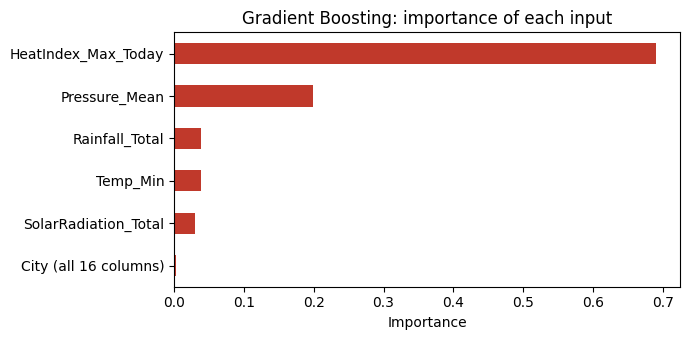

HeatIndex_Max_Today      0.690
Pressure_Mean            0.199
Rainfall_Total           0.039
Temp_Min                 0.038
SolarRadiation_Total     0.030
City (all 16 columns)    0.003
dtype: float64

In [8]:
BEST_WEIGHTS = balanced_weights(y) if best[3] == "balanced" else {}
final_model = make_gb(*best[:3]).fit(X, y, **BEST_WEIGHTS)
names = final_model.named_steps["columntransformer"].get_feature_names_out()
names = [n.replace("numbers__", "").replace("city__City_", "City: ") for n in names]
imp = pd.Series(final_model.named_steps["gradientboostingclassifier"].feature_importances_, index=names).sort_values()
inputs_imp = imp[[n for n in imp.index if not n.startswith("City: ")]]
city_total = imp[[n for n in imp.index if n.startswith("City: ")]].sum()
grouped = pd.concat([inputs_imp, pd.Series({"City (all 16 columns)": city_total})]).sort_values()
ax = grouped.plot(kind="barh", figsize=(7, 3.5), color="#C0392B")
ax.set_xlabel("Importance"); ax.set_title("Gradient Boosting: importance of each input")
plt.tight_layout(); plt.show()
grouped.sort_values(ascending=False).round(3)

## 6. Fit on all training days and save
Saved so the group can compare or load it later. No test day was used to choose or fit it.

In [9]:
os.makedirs(f"{ROOT}/models", exist_ok=True)
joblib.dump(final_model, f"{ROOT}/models/gradient_boosting.joblib")
print("saved:", f"{ROOT}/models/gradient_boosting.joblib")

saved: /tmp/hc/models/gradient_boosting.joblib


## 7. Numbers for Section 5.3 and the 6.2 table

In [10]:
print("Best setting:", dict(zip(["learning_rate", "max_depth", "n_trees", "sample_weight"], best)))
print()
for k, label in [("accuracy", "accuracy"), ("macro_f1", "macro F1 over all levels"), ("macro_f1_core3", "macro F1 over the 3 core levels"),
                 ("danger_recall", "Danger recall"), ("danger_precision", "Danger precision")]:
    print(f"{label:<34}{fmt(best_summary, k)}")
print()
print("Row for table 6.2:", f"{fmt(best_summary,'macro_f1')} / {fmt(best_summary,'macro_f1_core3')} | {fmt(best_summary,'accuracy')} | {fmt(best_summary,'danger_recall')} | {fmt(best_summary,'danger_precision')}")

Best setting: {'learning_rate': 0.1, 'max_depth': 2, 'n_trees': 200, 'sample_weight': 'balanced'}

accuracy                          0.790 ± 0.037
macro F1 over all levels          0.578 ± 0.092
macro F1 over the 3 core levels   0.643 ± 0.045
Danger recall                     0.670 ± 0.228
Danger precision                  0.381 ± 0.108

Row for table 6.2: 0.578 ± 0.092 / 0.643 ± 0.045 | 0.790 ± 0.037 | 0.670 ± 0.228 | 0.381 ± 0.108
